# Compare your data to mobility laws

**Question.** Do the movements in my data follow the regularities reported for human mobility, and what are their parameters?

**You will get** three fitted laws with their parameters and plots: the truncated power law of jump lengths, the universal visitation law (how often people visit places at each distance), and the lognormal distribution of the number of distinct places a person visits per day.

**Prerequisites.** [Measure individual mobility](measure-individual-mobility.md) and [Population measures and flows](population-measures.md). About a minute in a clean local environment (see the run-time table at the end).

**Data.** [Brightkite](https://snap.stanford.edu/data/loc-brightkite.html) check-ins (Stanford SNAP, 2008 to 2010): the first 300,000 rows (about 4 MB of the 60 MB file) with `fastmob.data.load_brightkite`, users with at least 100 check-ins (about 306). For the stay-based laws each check-in is treated as a 30-minute stay (an assumption). The notebook stops if the download fails.

> **Requires `fastmob` 0.3.4 or newer**, which provides the dataset loaders `fastmob.data.load_geolife` and `load_brightkite` (0.3.3 has them but caches GeoLife files across calls).

In [1]:
import time
from contextlib import contextmanager

_NOTEBOOK_START = time.perf_counter()
PHASES = {}


@contextmanager
def phase(name):
    """Add the wall-clock time of the block to PHASES[name]."""
    start = time.perf_counter()
    try:
        yield
    finally:
        PHASES[name] = PHASES.get(name, 0.0) + time.perf_counter() - start

In [2]:
with phase("setup"):
    get_ipython().run_line_magic("pip", "install -q 'fastmob>=0.3.4' pandas matplotlib")

In [3]:
import fastmob.data

assert hasattr(fastmob.data, "load_geolife") and hasattr(fastmob.data, "load_brightkite"), (
    "This notebook needs fastmob 0.3.4 or newer (older releases lack the dataset loaders or have a loader caching bug)."
)

In [4]:
import tempfile
from pathlib import Path

cache_status = "cached (files from an earlier run were reused)" if (Path(tempfile.gettempdir()) / "fastmob_data" / "brightkite").exists() else "cold (nothing cached before this run)"

## Load and clean

As in the previous notebooks, we drop placeholder and invalid coordinates and users with fewer than 100 check-ins.

In [5]:
import fastmob
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fastmob.data import load_brightkite
from fastmob.measures import fitting

with phase("download and load"):
    raw = load_brightkite(max_rows=300_000).to_pandas()

raw = raw[~(((raw["lat"] == 0) & (raw["lng"] == 0)) | (raw["lat"].abs() >= 90))]
counts = raw.groupby("uid").size()
checkins = raw[raw["uid"].isin(counts[counts >= 100].index)].sort_values(["uid", "datetime"]).reset_index(drop=True)
print(len(checkins), "check-ins by", checkins["uid"].nunique(), "users")

283543 check-ins by 306 users


## Law 1: jump lengths follow a truncated power law

Human jump lengths are heavy-tailed: short moves are common, long ones rare but not negligible, up to a cutoff. `fit_values_to_truncated_powerlaw` fits $P(\Delta r) \propto (\Delta r + \Delta r_0)^{-\beta} \exp(-\Delta r / \kappa)$ to a log-spaced histogram of positive jumps and returns the four parameters `(c, r0, beta, kappa)` plus the histogram it fitted. `log_truncated_powerlaw` evaluates the fitted curve.

In [6]:
with phase("analysis"):
    jumps = fastmob.jump_lengths(checkins)
    values = np.concatenate(jumps["jump_lengths"].to_list())
    values = values[np.isfinite(values) & (values > 0)]
    params, x, y = fitting.fit_values_to_truncated_powerlaw(values)
    curve = np.exp(fitting.log_truncated_powerlaw(x, *params))

c, r0, beta, kappa = params
print(f"{len(values):,} positive jumps, median {np.median(values):.1f} km")
print(f"beta = {beta:.2f}, r0 = {r0:.2f} km, kappa = {kappa:,.0f} km")

133,372 positive jumps, median 7.1 km
beta = 1.61, r0 = 2.40 km, kappa = 143,421 km


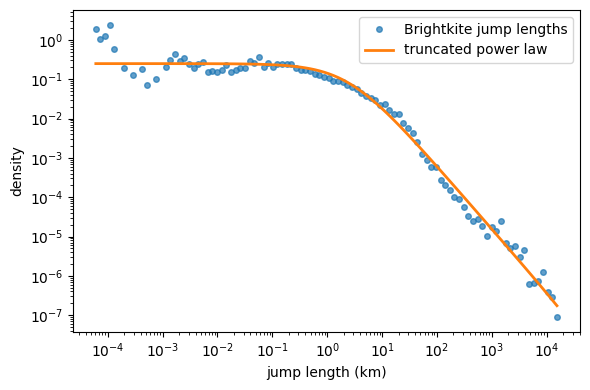

In [7]:
with phase("plotting"):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.loglog(x, y, "o", ms=4, alpha=0.7, label="Brightkite jump lengths")
    ax.loglog(x, curve, "-", lw=2, label="truncated power law")
    ax.set_xlabel("jump length (km)")
    ax.set_ylabel("density")
    ax.legend()
    fig.tight_layout()
    plt.show()

There are 133,372 positive jumps with a median of 7.1 km. The fit gives beta = 1.61 and r0 = 2.4 km: below a few kilometres the density is flat, above it falls as a power law of about -1.6. The cutoff kappa (143,421 km) is far larger than the size of the Earth, so no cutoff is detectable here and the curve is effectively a plain power law up to the longest jumps (about 15,000 km). The curve follows the data over seven orders of magnitude; the points at the shortest lengths (below about 1 m) are noisy.

## Law 2: the universal visitation law

The visitation law says that the frequency $f$ with which a person visits a place falls with the product of the visit frequency and the distance $r$: the density of visits $\rho$ of places with a given $rf$ follows $\rho = \mu (rf)^{-\eta}$. `fit_visitation_law` takes stays (here the 30-minute check-in stays on an H3 grid of resolution 8), computes distance $r$ to each person's home and distinct-day frequency $f$ for each place, and fits $\eta$ and $\mu$. The result is a `VisitationLawFit` with the per-user-place `data`, the aggregate `spectrum` that was fitted, and the parameters.

In [8]:
stays = fastmob.Staypoints(pd.DataFrame({
    "uid": checkins["uid"], "lat": checkins["lat"], "lng": checkins["lng"],
    "started_at": checkins["datetime"], "finished_at": checkins["datetime"] + pd.Timedelta(minutes=30),
}))
with phase("analysis"):
    places, stays_at = stays.generate_global_locations(h3_resolution=8)
    visitation = fitting.fit_visitation_law(stays_at, locations=places)

print(f"eta = {visitation.eta:.2f}, mu = {visitation.mu:.2f}, R2 = {visitation.r2:.2f}; {len(visitation.data)} user-place pairs, {len(visitation.spectrum)} spectrum points")
visitation.spectrum.head()

eta = 0.77, mu = 0.20, R2 = 0.97; 32225 user-place pairs, 30 spectrum points


,rf,rho
0,0.637364,0.363783
1,1.035673,0.337959
2,1.682898,0.177953
3,2.734594,0.117504
4,4.443529,0.065546


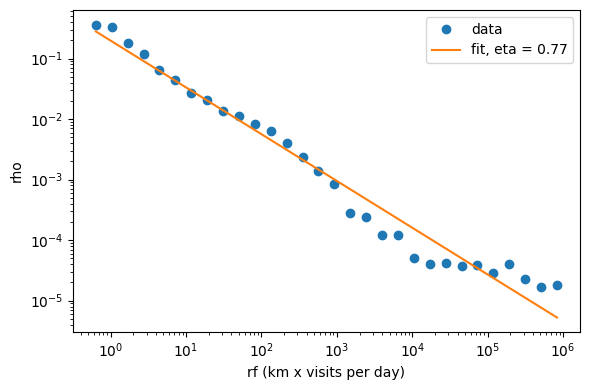

In [9]:
with phase("plotting"):
    spectrum = visitation.spectrum
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.loglog(spectrum["rf"], spectrum["rho"], "o", label="data")
    ax.loglog(spectrum["rf"], visitation.mu * spectrum["rf"] ** -visitation.eta, "-", label=f"fit, eta = {visitation.eta:.2f}")
    ax.set_xlabel("rf (km x visits per day)")
    ax.set_ylabel("rho")
    ax.legend()
    fig.tight_layout()
    plt.show()

The fitted exponent is eta = 0.77 with R² = 0.97 on 30 spectrum points: the density of places falls roughly as the 0.8 power of r times f. The line follows the data well over four orders of magnitude and drifts above the data for rf above about 10³ (km per visit per day), where the data flatten, so the fit describes the bulk and not the far tail.

## Law 3: distinct places per day are lognormal

`fit_daily_location_lognormal` counts, for each person and day, the number of distinct places visited, and fits a lognormal distribution to those counts. It returns the values (1, 2, 3, ... places), their observed probability, and the fitted $\mu$ and $\sigma$ of the lognormal.

In [10]:
with phase("analysis"):
    n_places, observed, mu, sigma = fitting.fit_daily_location_lognormal(stays_at, locations=places)

print(f"mu = {mu:.2f}, sigma = {sigma:.2f}; share of person-days with 1 place: {observed[0]:.0%}, with 2 places: {observed[1]:.0%}")

mu = 0.44, sigma = 0.54; share of person-days with 1 place: 55%, with 2 places: 25%


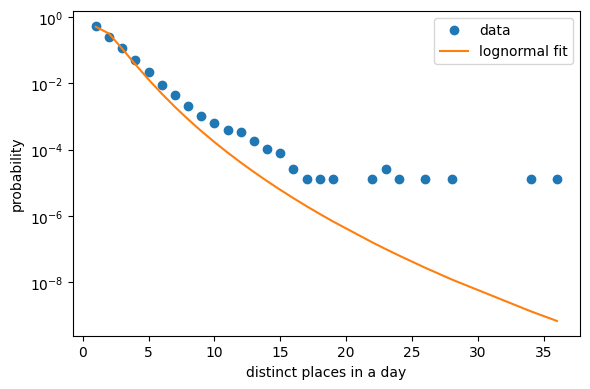

In [11]:
with phase("plotting"):
    k = np.array(n_places)
    pdf = np.exp(-((np.log(k) - mu) ** 2) / (2 * sigma**2)) / (k * sigma * np.sqrt(2 * np.pi))
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.semilogy(k, observed, "o", label="data")
    ax.semilogy(k, pdf / pdf.sum() * sum(observed), "-", label="lognormal fit")
    ax.set_xlabel("distinct places in a day")
    ax.set_ylabel("probability")
    ax.legend()
    fig.tight_layout()
    plt.show()

Fitted mu = 0.44 and sigma = 0.54. 55% of the person-days have a single place and 25% have two. The lognormal follows the first few points but falls well below the data from about 8 places a day on: the observed tail is heavier, with a few person-days of 20 to 35 places. For these data a heavier-tailed distribution would fit better.

## Interpretation and limits

- A fitted exponent is only meaningful with an uncertainty and a stated range. These fits report point estimates from a log-spaced histogram; they do not give confidence intervals, so do not over-read differences in the second decimal.
- Check-in data over-represent short, social, urban movement and skip travel that is not checked in. Compare with literature values only for similar data types (mobile-phone, GPS or check-in data give different parameters).
- The visitation-law and lognormal fits depend on the assumed 30-minute stay and the grid resolution (H3 level 8).
- Fit quality here is judged by eye and by $R^2$ of the spectrum; it is not a goodness-of-fit test against alternatives (such as a plain power law or exponential).

## Next steps

- Compare the fitted law with a model, and quantify the difference: [Fit and compare distributions](fit-and-evaluate.md).
- Generate trajectories that follow these laws: [Generate mobility with models](generate-mobility.md).

## Related API

[`truncated_powerlaw.fit_values_to_truncated_powerlaw`](https://gefgu.github.io/fastmob/reference/fitting/#fastmob.measures.fitting.truncated_powerlaw.fit_values_to_truncated_powerlaw) ·
[`truncated_powerlaw.log_truncated_powerlaw`](https://gefgu.github.io/fastmob/reference/fitting/#fastmob.measures.fitting.truncated_powerlaw.log_truncated_powerlaw) ·
[`visitation_law.fit_visitation_law`](https://gefgu.github.io/fastmob/reference/fitting/#fastmob.measures.fitting.visitation_law.fit_visitation_law) ·
[`visitation_law.VisitationLawFit`](https://gefgu.github.io/fastmob/reference/fitting/#fastmob.measures.fitting.visitation_law.VisitationLawFit) ·
[`daily_location_lognormal.fit_daily_location_lognormal`](https://gefgu.github.io/fastmob/reference/fitting/#fastmob.measures.fitting.daily_location_lognormal.fit_daily_location_lognormal)

## Run time

Measured by the notebook's own wall clock.

In [12]:
import datetime
import platform
from importlib.metadata import version

import pandas as pd

total = time.perf_counter() - _NOTEBOOK_START
measured = sum(PHASES.values())
timing = pd.DataFrame({"seconds": {**PHASES, "untimed cells and display": total - measured, "total notebook runtime": total}}).round(2)
print(timing.to_string())
print()
print("Download:", 'about 4 MB of the 60 MB Brightkite file (stream stopped after 300,000 rows)')
print("Cache:", cache_status)
print("Rows analysed:", len(checkins))
print("Environment: Python", platform.python_version(), "| fastmob", version("fastmob"), "| pandas", version("pandas"),
      "| measured", datetime.datetime.now(datetime.timezone.utc).date().isoformat())

                           seconds
setup                        27.07
download and load            15.02
analysis                      4.00
plotting                      5.71
untimed cells and display     3.24
total notebook runtime       55.04

Download: about 4 MB of the 60 MB Brightkite file (stream stopped after 300,000 rows)
Cache: cold (nothing cached before this run)
Rows analysed: 283543


Environment: Python 3.10.12 | fastmob 0.3.4 | pandas 2.3.3 | measured 2026-10-27
